# 7BUIS010W Data Warehousing & Business Intelligence – Coursework 2
## S&P 500 Stock Segmentation: Daily Return, Beta and Annual Volatility

**Module:** 7BUIS010W  
**Coursework:** CW2 (Group Coursework, 50%)  
**Period analysed:** 01-01-2022 to 01-01-2025  
**Methods:** Agglomerative Clustering, K-Means

---

### Notebook structure
1. **Task A** – Data loading, cleaning, metric calculation (Daily Return, Beta, Annual Volatility)
2. **Task B** – Stock segmentation with Agglomerative Clustering and K-Means
3. **Task C** – Cluster review and visualisations supporting the report

## 0. Environment setup

In [1]:
# Install required packages (Colab usually has most of these already)
!pip install yfinance yahoofinancials --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.9/51.9 kB 1.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [2]:
import pandas as pd
import numpy as np
import yfinance as yf
from yahoofinancials import YahooFinancials
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy import stats

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Environment ready.')

Environment ready.


---
## TASK A – Data Loading, Cleaning and Metric Calculation

### A.1 Extract S&P 500 tickers from Wikipedia using Pandas

In [3]:
import requests
from io import StringIO

WIKI_URL = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'

# Wikipedia 403 veriyor çünkü pandas default User-Agent göndermiyor.
# requests ile manuel header ekleyip HTML'i alıyoruz, sonra pandas'a veriyoruz.
headers = {
    'User-Agent': 'Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) '
                  'AppleWebKit/537.36 (KHTML, like Gecko) '
                  'Chrome/120.0.0.0 Safari/537.36'
}
response = requests.get(WIKI_URL, headers=headers)
response.raise_for_status()

wiki_tables = pd.read_html(StringIO(response.text))
sp500_table = wiki_tables[0]

print(f'Constituents table shape: {sp500_table.shape}')
sp500_table.head()

Constituents table shape: (503, 8)


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


In [4]:
# Yahoo Finance uses a hyphen instead of a dot for class-share tickers (e.g. BRK.B becomes BRK-B).
tickers = sp500_table['Symbol'].astype(str).str.replace('.', '-', regex=False).tolist()

# Persist the ticker list and the metadata table so reviewers can verify the extraction.
sp500_table.to_csv('sp500_constituents.csv', index=False)
pd.Series(tickers, name='Ticker').to_csv('sp500_tickers.csv', index=False)

print(f'Extracted {len(tickers)} tickers.')
print('First 10 tickers:', tickers[:10])

Extracted 503 tickers.
First 10 tickers: ['MMM', 'AOS', 'ABT', 'ABBV', 'ACN', 'ADBE', 'AMD', 'AES', 'AFL', 'A']


### A.2 Load daily market performance using yfinance and YahooFinancials

The brief specifies the period **01-01-2022 to 01-01-2025** and asks for the use of `yfinance` and `YahooFinancials`. We use `yfinance` for the bulk download (efficient batch retrieval) and `YahooFinancials` to pull the S&P 500 index series, which gives us the benchmark needed for beta.

In [5]:
START_DATE = '2022-01-01'
END_DATE = '2025-01-01'

# Bulk download of all S&P 500 constituents using yfinance.
raw_prices = yf.download(
    tickers=tickers,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,   # adjust for splits and dividends
    progress=True,
    group_by='ticker',
    threads=True,
)

print(f'Raw download shape: {raw_prices.shape}')
raw_prices.head()

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
2 Failed downloads:
ERROR:yfinance:['SNDK', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2022-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1641013200, endDate = 1735707600")')


Raw download shape: (753, 2517)


Ticker             DGX                                               \
Price             Open        High         Low       Close   Volume   
Date                                                                  
2022-01-03  157.640639  157.841945  149.048547  150.384491  1232500   
2022-01-04  150.064248  150.521761  143.082596  144.757095  1945700   
2022-01-05  144.958440  146.248630  143.814657  143.951920  1193900   
2022-01-06  143.128375  146.303517  142.332307  144.885223   945400   
2022-01-07  145.269532  145.388489  142.387205  142.625107   729800   

Ticker            VTR                                            ...  \
Price            Open       High        Low      Close   Volume  ...   
Date                                                             ...   
2022-01-03  44.426764  45.041157  44.054666  44.937317  2270800  ...   
2022-01-04  45.153660  46.737238  45.032512  46.105537  2480600  ...   
2022-01-05  46.477637  47.230489  45.629600  45.724789  2147900  ...   
2022-01-06  46.226685  46.564172  45.811320  46.105537  2044200  ...   
2022-01-07  45.923819  47.014154  45.776712  46.399757  2798400  ...   

Ticker            MDT                                                   ELV  \
Price            Open       High        Low      Close   Volume        Open   
Date                                                                          
2022-01-03  89.987411  92.770619  89.664592  92.569946  7797800  434.074615   
2022-01-04  92.247120  93.782677  91.950474  92.822952  7680600  437.806382   
2022-01-05  93.477323  95.091406  92.482698  92.491425  7206000  433.266263   
2022-01-06  92.735716  93.189402  91.278679  91.584045  5207000  419.063465   
2022-01-07  90.737739  92.334376  90.615592  91.749817  5142200  409.663833   

Ticker                                                   
Price             High         Low       Close   Volume  
Date                                                     
2022-01-03  437.110703  428.745044  436.950897   927200  
2022-01-04  438.962547  430.098706  430.662689   957300  
2022-01-05  437.204708  430.549758  430.709564   835300  
2022-01-06  425.737204  406.975561  413.066528  1763000  
2022-01-07  412.098361  400.687202  408.874268  1355400  

[5 rows x 2517 columns]

In [6]:
# Pull adjusted closing prices into a flat (date x ticker) frame.
if isinstance(raw_prices.columns, pd.MultiIndex):
    close_prices = raw_prices.xs('Close', axis=1, level=1)
else:
    close_prices = raw_prices['Close'].to_frame()

print(f'Close-price frame shape (rows=trading days, cols=tickers): {close_prices.shape}')
close_prices.head()

Close-price frame shape (rows=trading days, cols=tickers): (753, 503)


Ticker,DGX,VTR,FTV,AZO,CIEN,IRM,DVN,BX,FICO,IQV,...,AMCR,SW,EL,WTW,HSIC,CVNA,ADSK,KHC,MDT,ELV
Date,,,,,,,,,,,,,,,,,,,,,
2022-01-03,150.384491,44.937317,54.430645,2045.109985,77.379997,43.632633,37.153000,109.262634,443.130005,273.579987,...,49.673859,49.879475,345.944885,222.619980,77.430000,239.630005,283.720001,29.371468,92.569946,436.950897
2022-01-04,144.757095,46.105537,54.652603,2080.250000,75.879997,43.148006,38.856960,107.804420,445.829987,268.170013,...,50.468296,49.879475,347.411743,225.549576,79.279999,220.940002,278.190002,29.997255,92.822952,430.662689
2022-01-05,143.951920,45.724789,53.498432,2034.030029,75.379997,41.235046,38.000908,101.635048,425.890015,261.609985,...,50.551926,49.879475,332.697174,223.980820,78.989998,198.000000,264.320007,29.875347,92.491425,430.709564
2022-01-06,144.885223,46.105537,53.602009,2062.489990,74.379997,39.764194,39.435822,102.817169,443.529999,262.510010,...,50.133797,49.879475,332.024628,221.457581,77.860001,191.380005,264.109985,29.932243,91.584045,413.066528
2022-01-07,142.625107,46.399757,53.232082,2014.770020,73.050003,39.781193,39.859783,100.651398,440.049988,256.910004,...,50.677364,46.911674,331.594849,218.830444,78.949997,184.710007,262.320007,30.354853,91.749817,408.874268


In [7]:
# Use YahooFinancials to retrieve the S&P 500 index (^GSPC) as the benchmark for beta.
# Fallback: if YahooFinancials returns no price history (its Yahoo endpoint has changed
# since the coursework was run), download the same series with yfinance instead.
yf_index = YahooFinancials('^GSPC')
index_raw = yf_index.get_historical_price_data(START_DATE, END_DATE, 'daily')

if index_raw.get('^GSPC', {}).get('prices'):
    index_records = index_raw['^GSPC']['prices']
    index_df = pd.DataFrame(index_records)
    index_df['formatted_date'] = pd.to_datetime(index_df['formatted_date'])
    index_df = index_df.set_index('formatted_date').sort_index()
    index_close = index_df['close'].rename('SP500')
else:
    print('YahooFinancials returned no prices for ^GSPC; falling back to yfinance.')
    gspc = yf.download('^GSPC', start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)
    index_close = gspc['Close'].squeeze().rename('SP500')
    index_close.index = pd.to_datetime(index_close.index).tz_localize(None)

print(f'S&P 500 index series length: {len(index_close)}')
index_close.head()

S&P 500 index series length: 753


,SP500
formatted_date,
2022-01-03,4796.560059
2022-01-04,4793.540039
2022-01-05,4700.580078
2022-01-06,4696.049805
2022-01-07,4677.029785


### A.3 Identify and remove invalid data

In [8]:
print('Before cleaning:')
print(f'  rows (trading days): {close_prices.shape[0]}')
print(f'  cols (tickers):      {close_prices.shape[1]}')
print(f'  total NaNs:          {close_prices.isna().sum().sum()}')

# Step 1: drop tickers that are entirely missing (delisted, ticker change, download failure).
all_nan_tickers = close_prices.columns[close_prices.isna().all()].tolist()
print(f'  fully missing tickers: {len(all_nan_tickers)}')
close_prices = close_prices.drop(columns=all_nan_tickers)

# Step 2: drop tickers with more than 10% missing observations (insufficient history for stable beta).
missing_frac = close_prices.isna().mean()
thin_history = missing_frac[missing_frac > 0.10].index.tolist()
print(f'  tickers with >10% missing data: {len(thin_history)}')
close_prices = close_prices.drop(columns=thin_history)

# Step 3: forward-fill remaining short gaps, then drop residual NaN rows.
close_prices = close_prices.ffill().dropna()

print('\nAfter cleaning:')
print(f'  rows (trading days): {close_prices.shape[0]}')
print(f'  cols (tickers):      {close_prices.shape[1]}')
print(f'  total NaNs:          {close_prices.isna().sum().sum()}')

Before cleaning:
  rows (trading days): 753
  cols (tickers):      503
  total NaNs:          3651
  fully missing tickers: 2
  tickers with >10% missing data: 5

After cleaning:
  rows (trading days): 742
  cols (tickers):      496
  total NaNs:          0


### A.4 Daily Return

$$R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$$

In [9]:
# Daily returns for every stock.
daily_returns = close_prices.pct_change().dropna()

# Daily returns for the S&P 500 benchmark.
index_returns = index_close.pct_change().dropna()

# Align stock returns and index returns on common dates.
common_dates = daily_returns.index.intersection(index_returns.index)
daily_returns = daily_returns.loc[common_dates]
index_returns = index_returns.loc[common_dates]

print(f'Daily returns shape: {daily_returns.shape}')
daily_returns.head()

Daily returns shape: (741, 496)


Ticker,DGX,VTR,FTV,AZO,CIEN,IRM,DVN,BX,FICO,IQV,...,AMCR,SW,EL,WTW,HSIC,CVNA,ADSK,KHC,MDT,ELV
2022-01-20,-0.013023,0.011227,-0.012874,-0.006773,-0.033133,-0.015032,-0.006131,-0.006236,-0.017844,0.017147,...,-0.022562,0.005309,-0.027333,0.007415,-0.005634,0.005473,-0.007627,-0.004299,-0.015312,0.009882
2022-01-21,0.004010,0.022205,0.006310,0.004895,-0.015769,0.017844,-0.051614,-0.015955,-0.009142,-0.014116,...,-0.014839,0.000000,-0.013419,-0.011391,-0.007959,-0.141401,-0.052375,-0.001619,-0.004806,-0.024651
2022-01-24,0.004211,-0.014482,0.002787,0.015426,0.007241,0.023529,0.047919,-0.003552,0.029085,0.011413,...,-0.002511,-0.097796,0.016060,0.023045,0.011422,0.164025,0.025754,-0.016487,-0.013163,0.017982
2022-01-25,-0.008098,0.004254,-0.028905,-0.020886,-0.011471,-0.007888,0.060625,0.007770,-0.051610,-0.030652,...,-0.010906,0.000000,-0.025117,-0.018151,-0.022318,-0.072008,-0.047157,-0.004946,-0.000384,-0.022959
2022-01-26,-0.012976,-0.012322,-0.003578,-0.025501,-0.004796,0.005907,0.010340,0.011158,0.001248,-0.015197,...,-0.002545,0.056520,-0.005574,-0.004853,0.023790,-0.038081,-0.002139,-0.004695,-0.000768,-0.024455


In [10]:
# Mean daily return (used as the per-stock return metric for clustering).
mean_daily_return = daily_returns.mean().rename('Mean_Daily_Return')
mean_daily_return.describe()

,Mean_Daily_Return
count,496.000000
mean,0.000502
std,0.000683
min,-0.001485
25%,0.000084
50%,0.000434
75%,0.000812
max,0.004266


### A.5 Beta

$$\beta_i = \rho_{i, M} \cdot \frac{\sigma_i}{\sigma_M}$$

where $\rho_{i,M}$ is the correlation between stock $i$ returns and S&P 500 returns, $\sigma_i$ is the stock's standard deviation, and $\sigma_M$ is the index's standard deviation. This is the brief's exact formula.

In [11]:
# Vectorised beta calculation following the brief's formula.
stock_std = daily_returns.std()
index_std = index_returns.std()

# Correlation of every stock with the index.
correlations = daily_returns.apply(lambda col: col.corr(index_returns))

betas = (correlations * (stock_std / index_std)).rename('Beta')
betas.describe()

,Beta
count,496.000000
mean,0.944706
std,0.429326
min,0.137981
25%,0.638351
50%,0.911367
75%,1.153685
max,3.299275


In [12]:
print('Top 10 highest-beta stocks:')
print(betas.sort_values(ascending=False).head(10).round(3))
print('\nTop 10 lowest-beta stocks:')
print(betas.sort_values().head(10).round(3))

Top 10 highest-beta stocks:
Ticker
CVNA    3.299
COIN    2.965
XYZ     2.540
NVDA    2.260
APP     2.240
TTD     2.219
PLTR    2.175
MPWR    2.128
VRT     2.066
AMD     2.056
Name: Beta, dtype: float64

Top 10 lowest-beta stocks:
Ticker
GIS    0.138
CPB    0.142
SJM    0.206
HRL    0.246
LMT    0.249
KHC    0.250
JNJ    0.251
MRK    0.270
HSY    0.278
NOC    0.280
Name: Beta, dtype: float64


### A.6 Annual Volatility

$$\sigma_{\text{annual}} = \sigma_{\text{daily}} \times \sqrt{252}$$

(252 trading days in a US market year.)

In [13]:
annual_volatility = (daily_returns.std() * np.sqrt(252)).rename('Annual_Volatility')
annual_volatility.describe()

,Annual_Volatility
count,496.000000
mean,0.314287
std,0.114940
min,0.156764
25%,0.240952
50%,0.283724
75%,0.357567
max,1.346522


### A.7 Combined metric table

In [14]:
metrics = pd.concat([mean_daily_return, betas, annual_volatility], axis=1).dropna()

# Add sector information from the Wikipedia table for cluster profiling later on.
sector_lookup = sp500_table.set_index(
    sp500_table['Symbol'].astype(str).str.replace('.', '-', regex=False)
)['GICS Sector']
metrics['Sector'] = sector_lookup

metrics.to_csv('sp500_metrics.csv')
print(f'Final metric table shape: {metrics.shape}')
metrics.head(10)

Final metric table shape: (496, 4)


,Mean_Daily_Return,Beta,Annual_Volatility,Sector
Ticker,,,,
DGX,0.000273,0.465959,0.208558,Health Care
VTR,0.000487,0.704751,0.263629,Real Estate
FTV,0.000192,1.038555,0.249413,Industrials
AZO,0.000788,0.549765,0.241382,Consumer Discretionary
CIEN,0.000609,1.262069,0.400549,Information Technology
IRM,0.001522,0.908556,0.285993,Real Estate
DVN,0.000004,0.867242,0.397305,Energy
BX,0.001046,1.699776,0.404468,Financials
FICO,0.002310,1.246827,0.375089,Information Technology


### A.8 Visualising the segmentation power of the three metrics

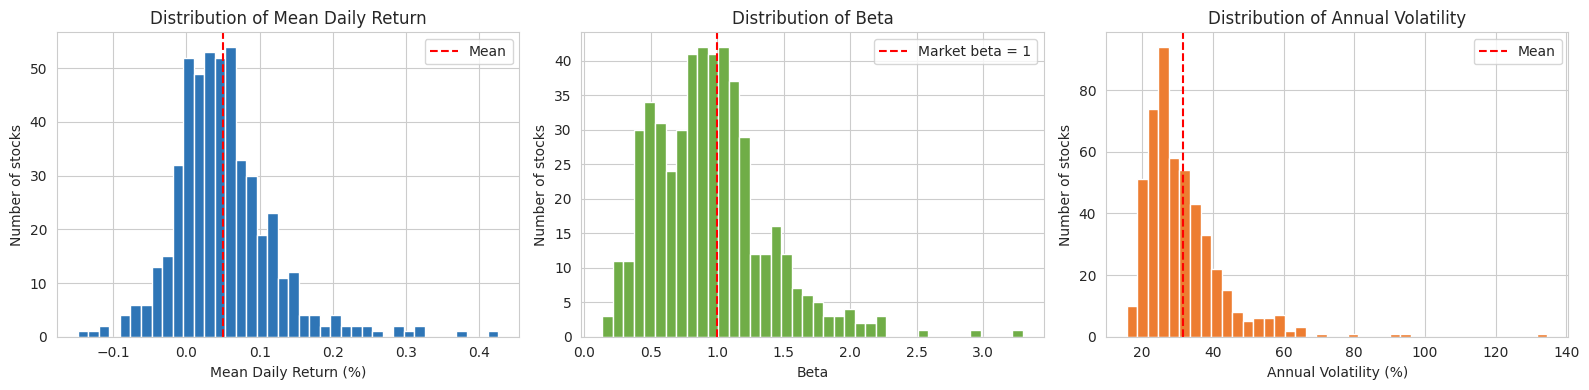

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(metrics['Mean_Daily_Return'] * 100, bins=40, color='#2E75B6', edgecolor='white')
axes[0].set_xlabel('Mean Daily Return (%)')
axes[0].set_ylabel('Number of stocks')
axes[0].set_title('Distribution of Mean Daily Return')
axes[0].axvline(metrics['Mean_Daily_Return'].mean() * 100, color='red', linestyle='--', label='Mean')
axes[0].legend()

axes[1].hist(metrics['Beta'], bins=40, color='#70AD47', edgecolor='white')
axes[1].set_xlabel('Beta')
axes[1].set_ylabel('Number of stocks')
axes[1].set_title('Distribution of Beta')
axes[1].axvline(1.0, color='red', linestyle='--', label='Market beta = 1')
axes[1].legend()

axes[2].hist(metrics['Annual_Volatility'] * 100, bins=40, color='#ED7D31', edgecolor='white')
axes[2].set_xlabel('Annual Volatility (%)')
axes[2].set_ylabel('Number of stocks')
axes[2].set_title('Distribution of Annual Volatility')
axes[2].axvline(metrics['Annual_Volatility'].mean() * 100, color='red', linestyle='--', label='Mean')
axes[2].legend()

plt.tight_layout()
plt.savefig('fig_metric_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

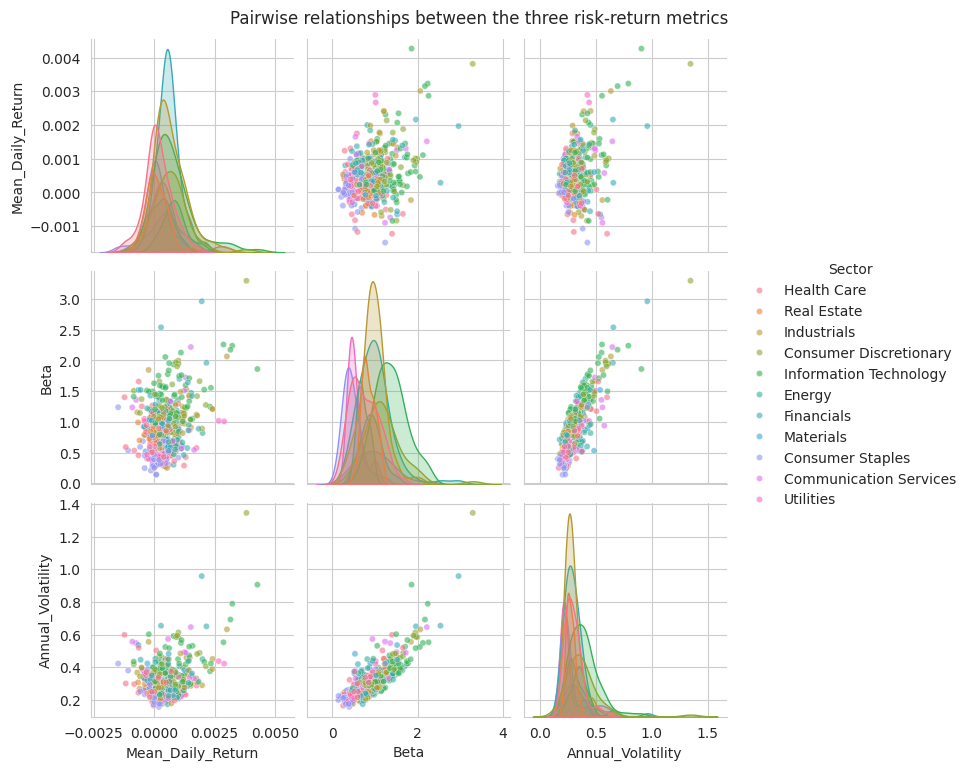

In [16]:
# Pairwise relationships between the three metrics, coloured by sector.
pair = sns.pairplot(
    metrics.reset_index(),
    vars=['Mean_Daily_Return', 'Beta', 'Annual_Volatility'],
    hue='Sector',
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 's': 20},
    height=2.5,
)
pair.fig.suptitle('Pairwise relationships between the three risk-return metrics', y=1.02)
plt.savefig('fig_pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

---
## TASK B – Stock Segmentation with Clustering

We use the three metrics (Mean Daily Return, Beta, Annual Volatility) as input features.

### B.0 Skew check and feature scaling

K-Means is sensitive to scale and to skewed features that drag the centroids. We:
1. Inspect skew on raw features.
2. Apply a robust standardisation (median, IQR) so extreme outliers do not dominate the distance metric.
3. Cap remaining outliers at the 1st and 99th percentiles for K-Means specifically (the brief's Task B explicitly asks to *remove skew from the input data*).

In [17]:
feature_cols = ['Mean_Daily_Return', 'Beta', 'Annual_Volatility']
X_raw = metrics[feature_cols].copy()

# Skew before any treatment.
skew_before = X_raw.apply(lambda c: stats.skew(c))
print('Skew before treatment:')
print(skew_before.round(3))

Skew before treatment:
Mean_Daily_Return    1.253
Beta                 1.101
Annual_Volatility    2.884
dtype: float64


In [18]:
# Winsorise at 1st / 99th percentile to clip extreme outliers without changing rank order.
X_winsor = X_raw.copy()
for col in feature_cols:
    lo, hi = X_winsor[col].quantile([0.01, 0.99])
    X_winsor[col] = X_winsor[col].clip(lo, hi)

skew_after = X_winsor.apply(lambda c: stats.skew(c))
print('Skew after winsorising at 1st/99th percentile:')
print(skew_after.round(3))

# Standardise (zero mean, unit variance) so all three metrics contribute on the same scale.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_winsor)
X_scaled_df = pd.DataFrame(X_scaled, index=X_winsor.index, columns=feature_cols)
X_scaled_df.describe().round(3)

Skew after winsorising at 1st/99th percentile:
Mean_Daily_Return    1.003
Beta                 0.734
Annual_Volatility    1.375
dtype: float64


,Mean_Daily_Return,Beta,Annual_Volatility
count,496.000,496.000,496.000
mean,0.000,-0.000,0.000
std,1.001,1.001,1.001
min,-2.072,-1.684,-1.377
25%,-0.640,-0.738,-0.709
50%,-0.102,-0.072,-0.279
75%,0.481,0.519,0.463
max,3.700,3.120,3.466


### B.1 Agglomerative Clustering

Agglomerative clustering builds a hierarchy bottom up: every observation starts as its own cluster, and the algorithm iteratively merges the closest pair using Ward's linkage (which minimises within-cluster variance). The resulting dendrogram lets us inspect the natural cluster structure visually before committing to a value of N.

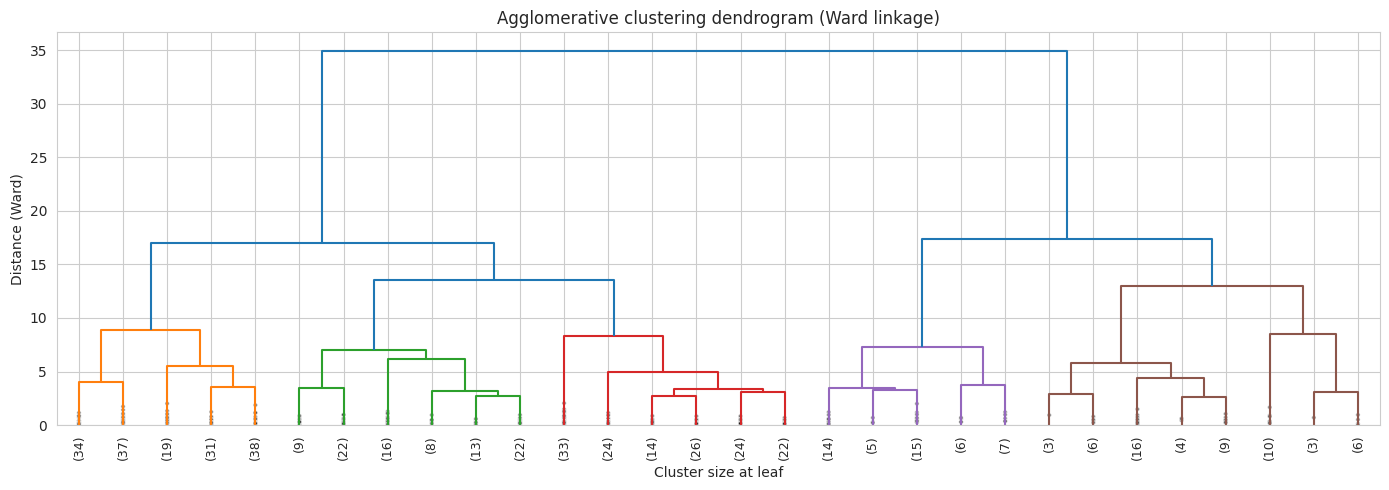

In [19]:
# Linkage matrix using Ward's method.
Z = linkage(X_scaled, method='ward')

fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(
    Z,
    truncate_mode='lastp',     # only show the last p merges for readability
    p=30,
    leaf_rotation=90,
    leaf_font_size=9,
    show_contracted=True,
    color_threshold=Z[-4, 2],  # cut threshold drawn at the 4-cluster solution
    ax=ax,
)
ax.set_title('Agglomerative clustering dendrogram (Ward linkage)')
ax.set_xlabel('Cluster size at leaf')
ax.set_ylabel('Distance (Ward)')
plt.tight_layout()
plt.savefig('fig_dendrogram.png', dpi=150, bbox_inches='tight')
plt.show()

Silhouette score by N (agglomerative):
2    0.4710
3    0.3979
4    0.2486
5    0.2527
6    0.2714
7    0.2438
8    0.2476
Name: Silhouette, dtype: float64


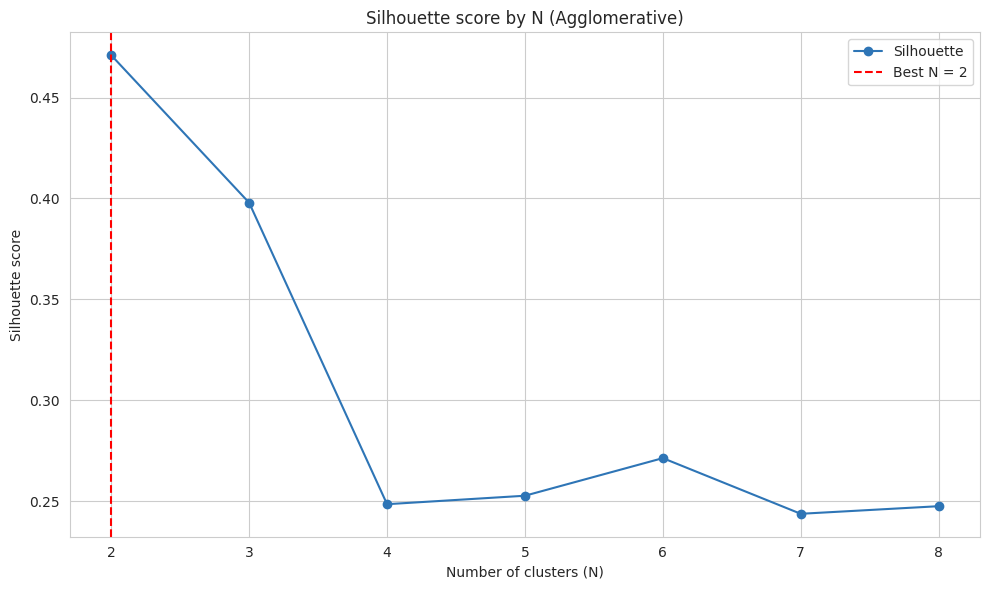

In [20]:
# Choose N via silhouette score across candidate values.
agg_silhouettes = {}
for n in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=n, linkage='ward').fit_predict(X_scaled)
    agg_silhouettes[n] = silhouette_score(X_scaled, labels)

agg_sil_series = pd.Series(agg_silhouettes, name='Silhouette')
print('Silhouette score by N (agglomerative):')
print(agg_sil_series.round(4))

fig, ax = plt.subplots()
agg_sil_series.plot(marker='o', color='#2E75B6', ax=ax)
ax.set_xlabel('Number of clusters (N)')
ax.set_ylabel('Silhouette score')
ax.set_title('Silhouette score by N (Agglomerative)')
ax.axvline(agg_sil_series.idxmax(), color='red', linestyle='--', label=f'Best N = {agg_sil_series.idxmax()}')
ax.legend()
plt.tight_layout()
plt.savefig('fig_agg_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

In [21]:
# Fit the chosen agglomerative model.
BEST_N = int(agg_sil_series.idxmax())
agg_model = AgglomerativeClustering(n_clusters=BEST_N, linkage='ward')
metrics['Agg_Cluster'] = agg_model.fit_predict(X_scaled)

agg_profile = metrics.groupby('Agg_Cluster')[feature_cols].agg(['mean', 'median', 'count']).round(4)
print(f'Agglomerative profile (N = {BEST_N}):')
agg_profile

Agglomerative profile (N = 2):


Mean_Daily_Return                  Beta                \
                         mean  median count    mean  median count   
Agg_Cluster                                                         
0                      0.0009  0.0009   104  1.5457  1.4553   104   
1                      0.0004  0.0004   392  0.7853  0.8193   392   

            Annual_Volatility                
                         mean  median count  
Agg_Cluster                                  
0                      0.4741  0.4350   104  
1                      0.2719  0.2677   392

### B.2 K-Means Clustering

K-Means partitions the data into K spherical clusters by minimising within-cluster sum of squares. To choose K we use:
1. The **elbow method** on inertia (within-cluster SSE).
2. The **silhouette score**.
3. The **Davies-Bouldin index** (lower is better) as a third confirmation.

In [22]:
k_range = range(2, 11)
inertias, sil_scores, db_scores = [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

diag = pd.DataFrame({
    'K': list(k_range),
    'Inertia': inertias,
    'Silhouette': sil_scores,
    'Davies_Bouldin': db_scores,
}).set_index('K')
diag.round(4)

,Inertia,Silhouette,Davies_Bouldin
K,,,
2,870.4963,0.4582,1.0162
3,656.8884,0.3468,1.0379
4,518.0440,0.3010,1.0649
5,442.0767,0.2867,1.0648
6,378.6697,0.2958,1.0049
7,338.8197,0.2909,0.9505
8,305.8670,0.2743,0.9733
9,275.8511,0.2827,0.9841
10,248.3712,0.2867,0.9389


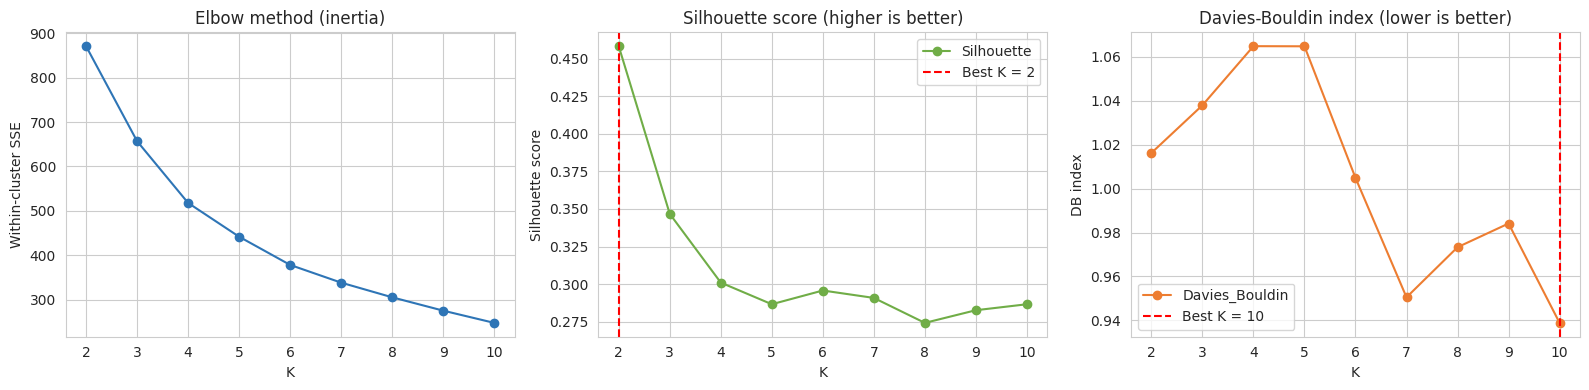

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

diag['Inertia'].plot(marker='o', color='#2E75B6', ax=axes[0])
axes[0].set_title('Elbow method (inertia)')
axes[0].set_xlabel('K')
axes[0].set_ylabel('Within-cluster SSE')

diag['Silhouette'].plot(marker='o', color='#70AD47', ax=axes[1])
axes[1].set_title('Silhouette score (higher is better)')
axes[1].set_xlabel('K')
axes[1].set_ylabel('Silhouette score')
axes[1].axvline(diag['Silhouette'].idxmax(), color='red', linestyle='--', label=f'Best K = {diag["Silhouette"].idxmax()}')
axes[1].legend()

diag['Davies_Bouldin'].plot(marker='o', color='#ED7D31', ax=axes[2])
axes[2].set_title('Davies-Bouldin index (lower is better)')
axes[2].set_xlabel('K')
axes[2].set_ylabel('DB index')
axes[2].axvline(diag['Davies_Bouldin'].idxmin(), color='red', linestyle='--', label=f'Best K = {diag["Davies_Bouldin"].idxmin()}')
axes[2].legend()

plt.tight_layout()
plt.savefig('fig_kmeans_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

In [24]:
# Choose K based on silhouette (primary) confirmed by Davies-Bouldin and the elbow.
BEST_K = int(diag['Silhouette'].idxmax())
kmeans_model = KMeans(n_clusters=BEST_K, random_state=RANDOM_STATE, n_init=20)
metrics['KMeans_Cluster'] = kmeans_model.fit_predict(X_scaled)

km_profile = metrics.groupby('KMeans_Cluster')[feature_cols].agg(['mean', 'median', 'count']).round(4)
print(f'K-Means profile (K = {BEST_K}):')
km_profile

K-Means profile (K = 2):


Mean_Daily_Return                  Beta                \
                            mean  median count    mean  median count   
KMeans_Cluster                                                         
0                         0.0004  0.0003   383  0.7769  0.8080   383   
1                         0.0009  0.0009   113  1.5136  1.4294   113   

               Annual_Volatility                
                            mean  median count  
KMeans_Cluster                                  
0                         0.2702  0.2661   383  
1                         0.4636  0.4241   113

In [25]:
# Cluster centroids in original feature units (inverse-transform).
centroids_scaled = kmeans_model.cluster_centers_
centroids_orig = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_orig, columns=feature_cols)
centroids_df.index.name = 'Cluster'
centroids_df['Size'] = metrics['KMeans_Cluster'].value_counts().sort_index().values
print('K-Means centroids in original units:')
centroids_df.round(4)

K-Means centroids in original units:


,Mean_Daily_Return,Beta,Annual_Volatility,Size
Cluster,,,,
0,0.0004,0.7776,0.2703,383
1,0.0009,1.4941,0.4511,113


---
## TASK C – Cluster Review and Visualisations

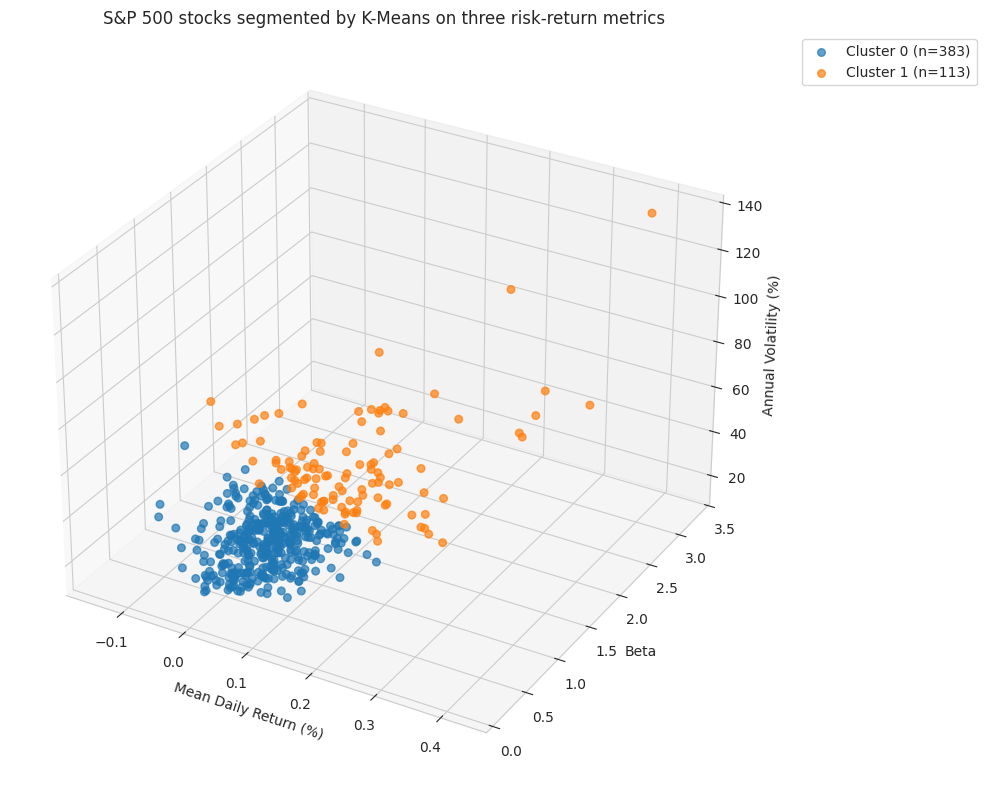

In [26]:
# 3D scatter showing the three metrics with K-Means cluster colouring.
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection='3d')

palette = sns.color_palette('tab10', n_colors=BEST_K)
for cluster_id in sorted(metrics['KMeans_Cluster'].unique()):
    sub = metrics[metrics['KMeans_Cluster'] == cluster_id]
    ax.scatter(
        sub['Mean_Daily_Return'] * 100,
        sub['Beta'],
        sub['Annual_Volatility'] * 100,
        s=30, alpha=0.7,
        color=palette[cluster_id],
        label=f'Cluster {cluster_id} (n={len(sub)})',
    )

ax.set_xlabel('Mean Daily Return (%)')
ax.set_ylabel('Beta')
ax.set_zlabel('Annual Volatility (%)')
ax.set_title('S&P 500 stocks segmented by K-Means on three risk-return metrics')
ax.legend(loc='upper left', bbox_to_anchor=(1.05, 1.0))
plt.tight_layout()
plt.savefig('fig_clusters_3d.png', dpi=150, bbox_inches='tight')
plt.show()

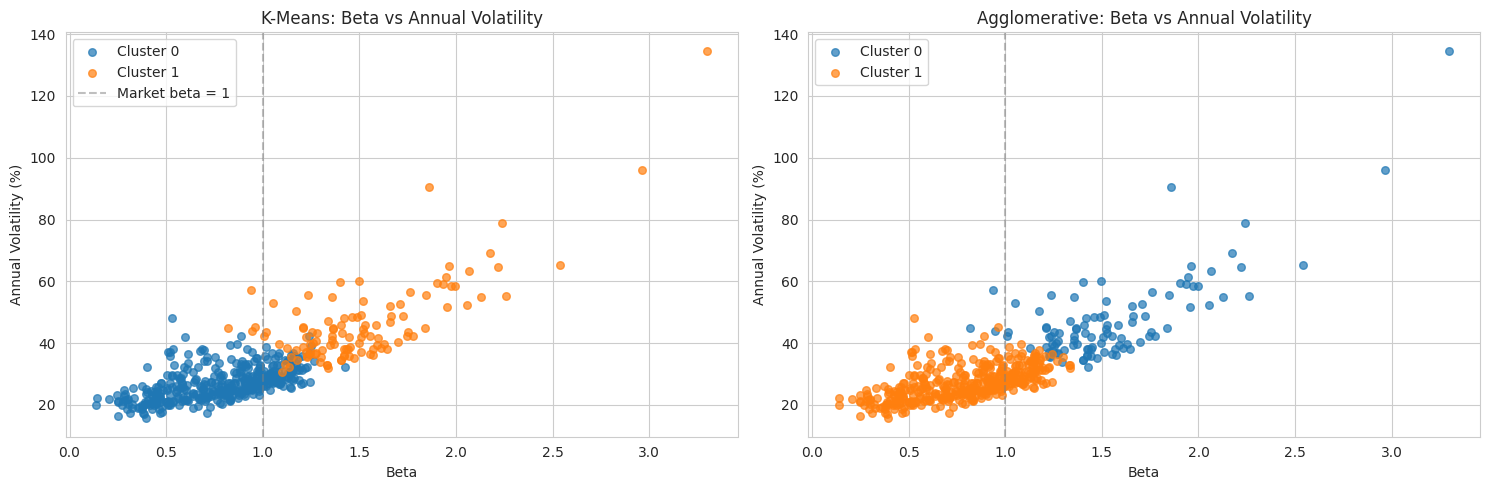

In [27]:
# 2D Beta vs Volatility view (the two risk dimensions investors usually trade off).
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for cluster_id in sorted(metrics['KMeans_Cluster'].unique()):
    sub = metrics[metrics['KMeans_Cluster'] == cluster_id]
    axes[0].scatter(sub['Beta'], sub['Annual_Volatility'] * 100,
                    s=30, alpha=0.7, color=palette[cluster_id],
                    label=f'Cluster {cluster_id}')
axes[0].set_xlabel('Beta')
axes[0].set_ylabel('Annual Volatility (%)')
axes[0].set_title('K-Means: Beta vs Annual Volatility')
axes[0].axvline(1.0, color='gray', linestyle='--', alpha=0.5, label='Market beta = 1')
axes[0].legend()

for cluster_id in sorted(metrics['Agg_Cluster'].unique()):
    sub = metrics[metrics['Agg_Cluster'] == cluster_id]
    axes[1].scatter(sub['Beta'], sub['Annual_Volatility'] * 100,
                    s=30, alpha=0.7, color=palette[cluster_id],
                    label=f'Cluster {cluster_id}')
axes[1].set_xlabel('Beta')
axes[1].set_ylabel('Annual Volatility (%)')
axes[1].set_title('Agglomerative: Beta vs Annual Volatility')
axes[1].axvline(1.0, color='gray', linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.savefig('fig_clusters_2d.png', dpi=150, bbox_inches='tight')
plt.show()

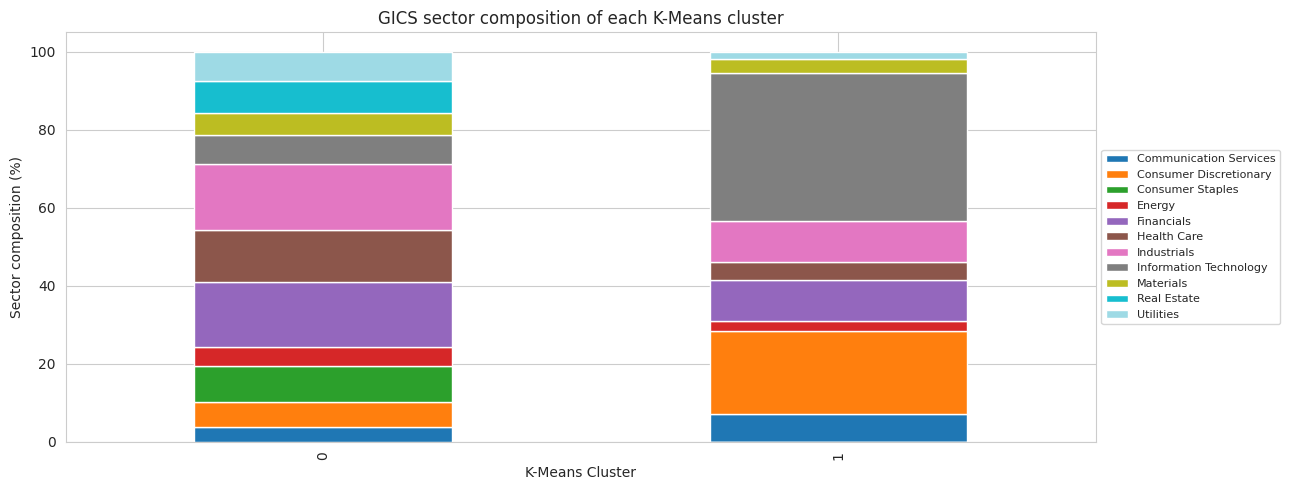

Sector,Communication Services,Consumer Discretionary,Consumer Staples,Energy,Financials,Health Care,Industrials,Information Technology,Materials,Real Estate,Utilities
KMeans_Cluster,,,,,,,,,,,
0,3.9,6.3,9.1,5.0,16.7,13.3,17.0,7.3,5.7,8.1,7.6
1,7.1,21.2,0.0,2.7,10.6,4.4,10.6,38.1,3.5,0.0,1.8


In [28]:
# Sector composition per K-Means cluster (used for the report's profile narrative).
sector_by_cluster = (
    metrics.groupby(['KMeans_Cluster', 'Sector']).size()
           .unstack(fill_value=0)
)
sector_by_cluster_pct = sector_by_cluster.div(sector_by_cluster.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(13, 5))
sector_by_cluster_pct.plot(kind='bar', stacked=True, ax=ax, colormap='tab20')
ax.set_xlabel('K-Means Cluster')
ax.set_ylabel('Sector composition (%)')
ax.set_title('GICS sector composition of each K-Means cluster')
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8)
plt.tight_layout()
plt.savefig('fig_sector_composition.png', dpi=150, bbox_inches='tight')
plt.show()

sector_by_cluster_pct.round(1)

In [29]:
# Final export: full table with cluster labels for the GitHub repo.
metrics.to_csv('sp500_metrics_with_clusters.csv')
print('Exports saved:')
for path in [
    'sp500_constituents.csv',
    'sp500_tickers.csv',
    'sp500_metrics.csv',
    'sp500_metrics_with_clusters.csv',
    'fig_metric_distributions.png',
    'fig_pairplot.png',
    'fig_dendrogram.png',
    'fig_agg_silhouette.png',
    'fig_kmeans_diagnostics.png',
    'fig_clusters_3d.png',
    'fig_clusters_2d.png',
    'fig_sector_composition.png',
]:
    print(f'  {path}')

Exports saved:
  sp500_constituents.csv
  sp500_tickers.csv
  sp500_metrics.csv
  sp500_metrics_with_clusters.csv
  fig_metric_distributions.png
  fig_pairplot.png
  fig_dendrogram.png
  fig_agg_silhouette.png
  fig_kmeans_diagnostics.png
  fig_clusters_3d.png
  fig_clusters_2d.png
  fig_sector_composition.png


---
## Summary of key numbers for the report

Run the cell below at the end of the notebook so the whole group can copy the values straight into the report.

In [30]:
print('=== KEY NUMBERS FOR THE REPORT ===')
print(f'Tickers extracted from Wikipedia       : {len(tickers)}')
print(f'Stocks after cleaning                  : {close_prices.shape[1]}')
print(f'Trading days in window                 : {close_prices.shape[0]}')
print()
print(f'Mean of mean daily returns             : {mean_daily_return.mean()*100:.4f}%')
print(f'Median beta                            : {betas.median():.3f}')
print(f'Mean annual volatility                 : {annual_volatility.mean()*100:.2f}%')
print()
print(f'Best N (Agglomerative, silhouette)     : {BEST_N}  (score = {agg_sil_series.max():.4f})')
print(f'Best K (K-Means, silhouette)           : {BEST_K}  (score = {diag["Silhouette"].max():.4f})')
print(f'Best K (K-Means, Davies-Bouldin)       : {diag["Davies_Bouldin"].idxmin()}  (DB = {diag["Davies_Bouldin"].min():.4f})')

=== KEY NUMBERS FOR THE REPORT ===
Tickers extracted from Wikipedia       : 503
Stocks after cleaning                  : 496
Trading days in window                 : 742

Mean of mean daily returns             : 0.0502%
Median beta                            : 0.911
Mean annual volatility                 : 31.43%

Best N (Agglomerative, silhouette)     : 2  (score = 0.4710)
Best K (K-Means, silhouette)           : 2  (score = 0.4582)
Best K (K-Means, Davies-Bouldin)       : 10  (DB = 0.9389)
